# Library vs Native Background Subtraction — Comparison (QVGA)

Compares the OpenCV/pybgs **library** backends against the pure-NumPy **native** reimplementations (`scr.models`), for runs at **QVGA (320x240)** resolution, using the pre-computed result trees under `results_*_qvga/`.

| mask | library results | native results |
| --- | --- | --- |
| **slow** | `results_qvga/` | `results_native_qvga/` |
| **fast** | `results_fast_qvga/` | `results_native_fast_qvga/` |

Each tree holds one sub-folder per frame-rate variant (`basic`, `1fps`, `0_5fps`, `0_1fps`), each with one sub-folder of `bin%06d.png` masks per sequence, plus an `eval_summary.csv` of F-measures.

The notebook produces:
1. Two F-measure comparison tables — **slow lib vs native**, **fast lib vs native**.
2. The **average mask difference** (fraction of pixels where the two masks disagree).
3. Numbers and graphs for both.

In [1]:
import glob
import os
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda v: f'{v:.4f}')

VARIANTS = ['basic', '1fps', '0_5fps', '0_1fps']
COMPARISONS = {
    'slow': {'lib': 'results_qvga', 'native': 'results_native_qvga'},
    'fast': {'lib': 'results_fast_qvga', 'native': 'results_native_fast_qvga'},
}
# Frames sampled per sequence for the mask-difference pass (1 = every frame).
SAMPLE_EVERY = 10

## 1. F-measure tables

Loaded from each tree's `eval_summary.csv`. For every frame-rate variant the table shows the library F-measure, the native F-measure, and their signed difference `Δ = lib − native`.

In [2]:
def load_summary(results_dir):
    """Load an eval_summary.csv, dropping the trailing average row."""
    df = pd.read_csv(Path(results_dir) / 'eval_summary.csv')
    return df[df['case'] != 'average'].set_index('case')[VARIANTS]


def comparison_table(lib_dir, native_dir):
    """Build a sequence x (variant, {lib, native, Δ}) F-measure table."""
    lib, native = load_summary(lib_dir), load_summary(native_dir)
    columns = {}
    for variant in VARIANTS:
        columns[(variant, 'lib')] = lib[variant]
        columns[(variant, 'native')] = native[variant]
        columns[(variant, 'Δ')] = lib[variant] - native[variant]
    table = pd.DataFrame(columns)
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    table.loc['average'] = table.mean()
    return table


slow_ftable = comparison_table(COMPARISONS['slow']['lib'], COMPARISONS['slow']['native'])
fast_ftable = comparison_table(COMPARISONS['fast']['lib'], COMPARISONS['fast']['native'])

### Table 1 — Slow: library vs native (F-measure)

In [3]:
slow_ftable

basic                  1fps               0_5fps         \
                      lib native       Δ    lib native      Δ    lib native   
case                                                                          
boats              0.5390 0.5391 -0.0001 0.1774 0.1774 0.0000 0.1633 0.1633   
busStation         0.6704 0.6704  0.0000 0.6786 0.6786 0.0000 0.6769 0.6769   
canoe              0.5575 0.5576 -0.0001 0.4313 0.4313 0.0000 0.4316 0.4316   
traffic            0.3643 0.3643  0.0000 0.2657 0.2657 0.0000 0.3847 0.3847   
tramCrossroad_1fps 0.1867 0.1867  0.0000 0.1867 0.1867 0.0000 0.1573 0.1573   
turnpike_0_5fps    0.4801 0.4801  0.0000 0.4801 0.4801 0.0000 0.4801 0.4801   
average            0.4663 0.4664 -0.0000 0.3700 0.3700 0.0000 0.3823 0.3823   

                          0_1fps                
                        Δ    lib native      Δ  
case                                            
boats              0.0000 0.1341 0.1341 0.0000  
busStation         0.0000 0.6772 0.6772 0.0000  
canoe              0.0000 0.5908 0.5908 0.0000  
traffic            0.0000 0.4786 0.4786 0.0000  
tramCrossroad_1fps 0.0000 0.1250 0.1250 0.0000  
turnpike_0_5fps    0.0000 0.4160 0.4160 0.0000  
average            0.0000 0.4036 0.4036 0.0000

### Table 2 — Fast: library vs native (F-measure)

In [4]:
fast_ftable

basic                 1fps               0_5fps         \
                      lib native      Δ    lib native      Δ    lib native   
case                                                                         
boats              0.2085 0.2085 0.0000 0.4505 0.4505 0.0000 0.4806 0.4806   
busStation         0.3643 0.3643 0.0000 0.5993 0.5993 0.0000 0.6461 0.6461   
canoe              0.3498 0.3498 0.0000 0.5532 0.5532 0.0000 0.5590 0.5590   
traffic            0.4291 0.4291 0.0000 0.4470 0.4470 0.0000 0.5815 0.5815   
tramCrossroad_1fps 0.6879 0.6879 0.0000 0.6879 0.6879 0.0000 0.7260 0.7260   
turnpike_0_5fps    0.6486 0.6486 0.0000 0.6486 0.6486 0.0000 0.6486 0.6486   
average            0.4480 0.4480 0.0000 0.5644 0.5644 0.0000 0.6070 0.6070   

                          0_1fps                
                        Δ    lib native      Δ  
case                                            
boats              0.0000 0.3912 0.3912 0.0000  
busStation         0.0000 0.6608 0.6608 0.0000  
canoe              0.0000 0.6079 0.6079 0.0000  
traffic            0.0000 0.5141 0.5141 0.0000  
tramCrossroad_1fps 0.0000 0.7045 0.7045 0.0000  
turnpike_0_5fps    0.0000 0.6712 0.6712 0.0000  
average            0.0000 0.5916 0.5916 0.0000

## 2. Average mask difference (lib vs native)

For every matched frame the two binary masks are compared pixel-by-pixel; the per-frame **disagreement** is the fraction of pixels where they differ (masks are 0/255, so this equals the mean absolute difference / 255). The value reported per sequence is that fraction averaged over the sampled frames, expressed as a percentage.

In [5]:
def frame_number(path):
    """Extract the frame number from a mask filename."""
    match = re.search(r'(\d+)', os.path.basename(path))
    return int(match.group(1)) if match else -1


def index_masks(directory):
    """Map frame number -> mask path for one sequence folder."""
    return {frame_number(p): p for p in glob.glob(os.path.join(directory, '*.png'))}


def sequence_mask_diff(dir_a, dir_b, sample_every):
    """Mean %% of pixels differing between matched masks of two folders."""
    a, b = index_masks(dir_a), index_masks(dir_b)
    common = sorted(set(a) & set(b))[::sample_every]
    if not common:
        return np.nan
    per_frame = []
    for number in common:
        mask_a = cv2.imread(a[number], cv2.IMREAD_GRAYSCALE) > 0
        mask_b = cv2.imread(b[number], cv2.IMREAD_GRAYSCALE) > 0
        per_frame.append(float((mask_a != mask_b).mean()))
    return float(np.mean(per_frame)) * 100.0


def mask_diff_table(lib_root, native_root, sample_every):
    """Sequence x variant table of mean mask-difference percentages."""
    sequences = sorted(
        p.name for p in (Path(lib_root) / 'basic').iterdir() if p.is_dir()
    )
    data = {
        variant: {
            seq: sequence_mask_diff(
                str(Path(lib_root) / variant / seq),
                str(Path(native_root) / variant / seq),
                sample_every,
            )
            for seq in sequences
        }
        for variant in VARIANTS
    }
    table = pd.DataFrame(data)[VARIANTS]
    table.loc['average'] = table.mean()
    return table


slow_diff = mask_diff_table(
    COMPARISONS['slow']['lib'], COMPARISONS['slow']['native'], SAMPLE_EVERY
)
fast_diff = mask_diff_table(
    COMPARISONS['fast']['lib'], COMPARISONS['fast']['native'], SAMPLE_EVERY
)

### Table 3 — Slow: mask difference (% pixels differing, lib vs native)

In [6]:
slow_diff

,basic,1fps,0_5fps,0_1fps
boats,0.0002,0.0001,0.0002,0.0003
busStation,0.0001,0.0000,0.0000,0.0000
canoe,0.0003,0.0003,0.0000,0.0000
traffic,0.0006,0.0004,0.0000,0.0000
tramCrossroad_1fps,0.0002,0.0002,0.0002,0.0000
turnpike_0_5fps,0.0001,0.0001,0.0001,0.0001
average,0.0003,0.0002,0.0001,0.0001


### Table 4 — Fast: mask difference (% pixels differing, lib vs native)

In [7]:
fast_diff

,basic,1fps,0_5fps,0_1fps
boats,0.0000,0.0000,0.0000,0.0000
busStation,0.0000,0.0000,0.0000,0.0000
canoe,0.0000,0.0000,0.0000,0.0000
traffic,0.0000,0.0000,0.0000,0.0000
tramCrossroad_1fps,0.0000,0.0000,0.0000,0.0000
turnpike_0_5fps,0.0000,0.0000,0.0000,0.0000
average,0.0000,0.0000,0.0000,0.0000


### Headline numbers

In [8]:
slow_f_max = slow_ftable.xs('Δ', axis=1, level=1).drop('average').abs().values.max()
fast_f_max = fast_ftable.xs('Δ', axis=1, level=1).drop('average').abs().values.max()
print(f'Slow — mean mask difference : {slow_diff.loc["average"].mean():.4f} % of pixels')
print(f'Fast — mean mask difference : {fast_diff.loc["average"].mean():.4f} % of pixels')
print(f'Slow — max |F_lib - F_native|: {slow_f_max:.5f}')
print(f'Fast — max |F_lib - F_native|: {fast_f_max:.5f}')

Slow — mean mask difference : 0.0001 % of pixels
Fast — mean mask difference : 0.0000 % of pixels
Slow — max |F_lib - F_native|: 0.00010
Fast — max |F_lib - F_native|: 0.00000


## 3. Graphs

### Mean F-measure per variant — library vs native

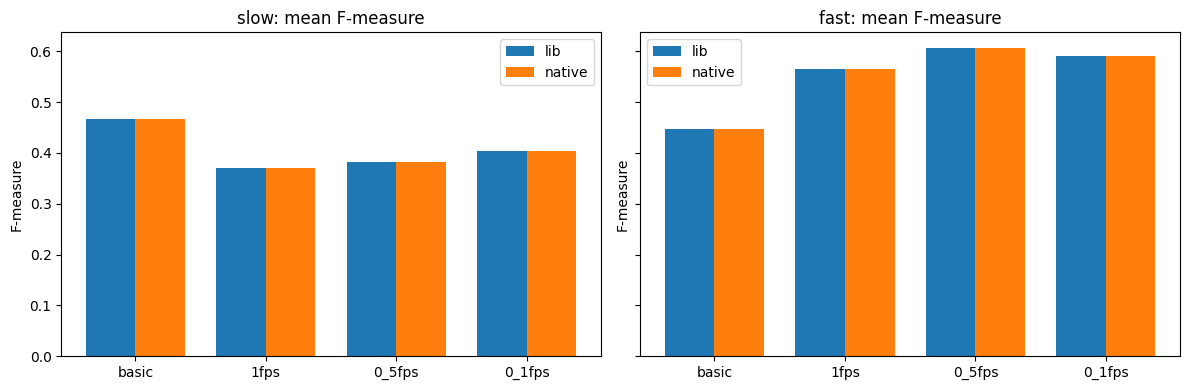

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, table) in zip(axes, [('slow', slow_ftable), ('fast', fast_ftable)]):
    lib_avg = [table.loc['average', (v, 'lib')] for v in VARIANTS]
    native_avg = [table.loc['average', (v, 'native')] for v in VARIANTS]
    x = np.arange(len(VARIANTS))
    width = 0.38
    ax.bar(x - width / 2, lib_avg, width, label='lib')
    ax.bar(x + width / 2, native_avg, width, label='native')
    ax.set_xticks(x)
    ax.set_xticklabels(VARIANTS)
    ax.set_title(f'{name}: mean F-measure')
    ax.set_ylabel('F-measure')
    ax.legend()
plt.tight_layout()
plt.show()

### Agreement scatter — every (sequence, variant) cell
Points on the dashed `y = x` line mean the native F-measure equals the library one.

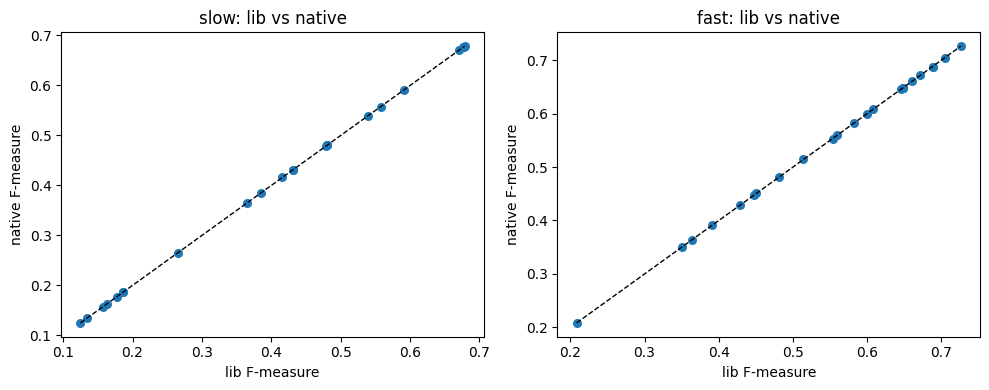

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, table) in zip(axes, [('slow', slow_ftable), ('fast', fast_ftable)]):
    lib = table.xs('lib', axis=1, level=1).drop('average').values.ravel()
    native = table.xs('native', axis=1, level=1).drop('average').values.ravel()
    ax.scatter(lib, native, s=30)
    lo, hi = min(lib.min(), native.min()), max(lib.max(), native.max())
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
    ax.set_xlabel('lib F-measure')
    ax.set_ylabel('native F-measure')
    ax.set_title(f'{name}: lib vs native')
plt.tight_layout()
plt.show()

### Mean mask difference per variant

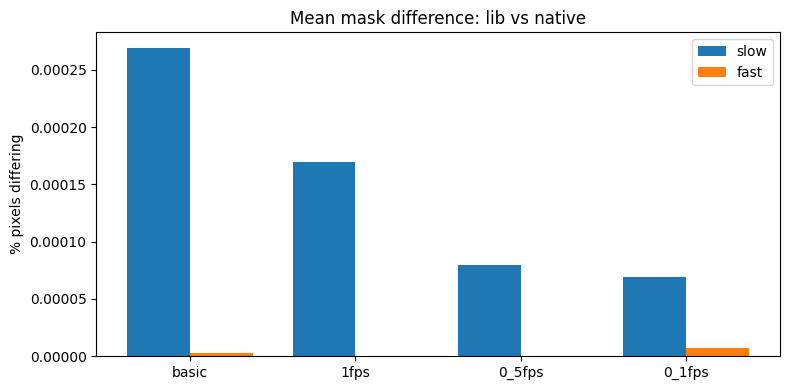

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(VARIANTS))
width = 0.38
ax.bar(x - width / 2, slow_diff.loc['average'].values, width, label='slow')
ax.bar(x + width / 2, fast_diff.loc['average'].values, width, label='fast')
ax.set_xticks(x)
ax.set_xticklabels(VARIANTS)
ax.set_ylabel('% pixels differing')
ax.set_title('Mean mask difference: lib vs native')
ax.legend()
plt.tight_layout()
plt.show()

### Mask-difference heatmaps (sequence x variant)

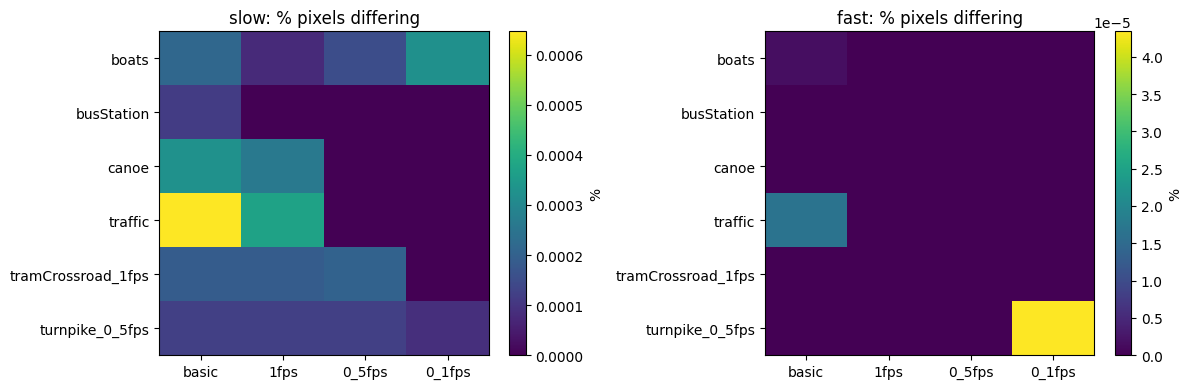

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, table) in zip(axes, [('slow', slow_diff), ('fast', fast_diff)]):
    grid = table.drop('average')
    image = ax.imshow(grid.values, aspect='auto', cmap='viridis')
    ax.set_xticks(range(len(VARIANTS)))
    ax.set_xticklabels(VARIANTS)
    ax.set_yticks(range(len(grid.index)))
    ax.set_yticklabels(grid.index)
    ax.set_title(f'{name}: % pixels differing')
    fig.colorbar(image, ax=ax, label='%')
plt.tight_layout()
plt.show()

## 4. Notes

* The tables above compare whichever backend was used to produce each results tree. When that backend is `running_average` (the default), the native model is algorithmically identical to the library one, so the F-measures and masks match to within floating-point rounding — the expected outcome and a check that the native port is faithful.
* To compare genuinely different algorithms (e.g. ViBe, MOG), regenerate the result trees with the matching `--implementation` / backend flags and re-run this notebook.
* `SAMPLE_EVERY` controls the mask-difference sampling; set it to `1` in cell 2 for an exact (slower) pass over every frame.